# Regression model for rate of bikes per hour

This script prepares data for the regression model. The actual model is run in `regression.R`.

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm
import seaborn as sns

In [2]:
import statsmodels.formula.api as smf

In [3]:
pd.options.mode.copy_on_write = True

## Load and merge data

In [4]:
agg_counts = pd.read_csv('data/aggregated_data.csv')

In [5]:
canbics = pd.read_csv("data/PP_CounterPoints_Cycle_Facilities_FULL_02JAN2025.csv")

In [6]:
canbics['can_bics_facility'] = canbics['can_bics_facility'].str.strip() # remove leading spaces

In [7]:
# Change North Vancouver to Vancouver
agg_counts.loc[agg_counts['geocoded_city'] == 'North Vancouver', 'geocoded_city'] = 'Vancouver'

In [8]:
agg_counts['count_year'] = agg_counts['year']

In [9]:
agg_counts.shape

(1859, 29)

In [10]:
agg_counts = agg_counts.merge(canbics[['grouped_counterpoint_id','cp_name','count_year', 
                                       'can_bics_facility', 'other_cycle_facility','comfort_class', 
                                       'google_street_month', 'google_street_year']].drop_duplicates(),
                 on = ('grouped_counterpoint_id', 'count_year'), how = 'left')

### Spatial access measures

Direct link to data: https://www150.statcan.gc.ca/n1/pub/27-26-0001/2023001/sam-msa-eng.zip

Data landing page here: https://www150.statcan.gc.ca/n1/pub/27-26-0001/272600012023001-eng.htm

In [11]:
# spatial access measures

sam_data = pd.read_csv("data/sam-msa-eng/acs_cycling.csv",
                      encoding='latin-1')

In [12]:
sam_data.columns

Index(['DBUID', 'CSDUID', 'CSDNAME', 'CMAUID', 'CMANAME', 'PRUID', 'PRCODE',
       'acs_idx_hf', 'acs_idx_emp', 'acs_idx_srf', 'acs_idx_psef',
       'acs_idx_ef', 'acs_idx_caf', 'acs_lvl_gs-1', 'acs_lvl_gs-3',
       'acs_lvl_gs-5'],
      dtype='object')

Get dissemination block for each counterpoint location

Direct link to dissemination block boundary file: https://www12.statcan.gc.ca/census-recensement/2021/geo/sip-pis/boundary-limites/files-fichiers/ldb_000a21a_e.zip

To download dissemination block boundary file:
- Go to Statistics Canada website here: https://www12.statcan.gc.ca/census-recensement/2021/geo/sip-pis/boundary-limites/index2021-eng.cfm?year=21
- Under "Type" select "Digital Boundary Files"
- Under "Statistical boundaries" select "Dissemination blocks"
- Under "Format" select "Shapefile"
- Select "Continue"
- Download and extract the zip file on the next page. 

In [13]:
def get_counterpoint_to_db(agg_counts, sam_data):
    import geopandas as gpd

    db_boundaries = gpd.read_file("data/ldb_000a21a_e/ldb_000a21a_e.shp")

    agg_counts_gdf = gpd.GeoDataFrame(
        agg_counts, geometry=gpd.points_from_xy(agg_counts['grouped_counterpoint_lng'],
                                                      agg_counts['grouped_counterpoint_lat']), crs="EPSG:4326"
    )

    unique_counterpoint_gdf = agg_counts_gdf.drop_duplicates(subset = 'grouped_counterpoint_id')
    unique_counterpoint_gdf = unique_counterpoint_gdf.to_crs(db_boundaries.crs)

    counterpoint_to_dbuid = {}
    for i, row in tqdm(unique_counterpoint_gdf.iterrows()):
        dbuid = db_boundaries[db_boundaries['geometry'].contains(row['geometry'])]['DBUID']
        assert len(dbuid) == 1
        counterpoint_to_dbuid[int(row['grouped_counterpoint_id'])] = int(dbuid.iloc[0])

    db_boundaries['DBUID'] = db_boundaries['DBUID'].astype('int')

    db_boundaries_sam = db_boundaries[db_boundaries['DBUID'].isin(sam_data['DBUID'])]

    assert db_boundaries_sam.shape[0] == sam_data.shape[0] # check that all of sam data is in there

    agg_counts['DBUID'] = agg_counts['grouped_counterpoint_id'].map(counterpoint_to_dbuid)
    agg_counts[['grouped_counterpoint_id', 'DBUID']].drop_duplicates().to_csv("data/counterpoint_to_dbuid.csv", index = None)

In [14]:
#counterpoint_id_info = pd.read_csv("counterpoint_id_groupings_edited_names.csv") # this file has counterpoint names edited by hand (more concise)
counterpoint_id_info = pd.read_csv("data/counterpoint_id_groupings.csv") # up to date for 2024

In [15]:
counterpoints = counterpoint_id_info[['grouped_counterpoint_id', 'grouped_counterpoint_lat', 'grouped_counterpoint_lng']].drop_duplicates()

In [16]:
agg_counts = agg_counts.merge(counterpoints, on = 'grouped_counterpoint_id', how = 'left')

In [17]:
try:
    counterpoint_to_dbuid = pd.read_csv("data/counterpoint_to_dbuid.csv")
    agg_counts = agg_counts.merge(counterpoint_to_dbuid, on = 'grouped_counterpoint_id', how = 'left')
    print("loaded counterpoint to DB mapping")
except:
    get_counterpoint_to_db(agg_counts, sam_data)
    counterpoint_to_dbuid = pd.read_csv("data/counterpoint_to_dbuid.csv")
    

loaded counterpoint to DB mapping


### Census population size data

In [18]:
# census subdivisions
csd_data = pd.read_csv("data/98100002-eng/98100002.csv")

The CSD code is a three‑digit code that is based on the Standard Geographical Classification. To uniquely identify each in Canada, the two‑digit province or territory (PR) code and the two‑digit census division (CD) code must precede the CSD code. For example:

In [19]:
# the data includes higher divisions as well, filter them out
csd_data = csd_data[csd_data['DGUID'].str.len() == 16]

In [20]:
csd_data['CSD_UID'] = csd_data['DGUID'].str[-7:]

In [21]:
# check that IDs match between files and all IDs are present (matching data years)
assert np.all(sam_data['CSDUID'].astype('int').isin(csd_data['CSD_UID'].astype('int')))

In [22]:
csd_data = csd_data.rename(columns = {'Population and dwelling counts (13): Population, 2021 [1]':'csd_population',
                                      'Population and dwelling counts (13): Population density per square kilometre, 2021 [11]':'csd_pop_density'})

In [23]:
csd_data['CSD_UID'] = csd_data['CSD_UID'].astype('int')
sam_data['CSDUID'] = sam_data['CSDUID'].astype('int')

In [24]:
sam_data.shape

(498547, 16)

In [25]:
sam_data = sam_data.merge(csd_data[['CSD_UID', 'csd_population', 'csd_pop_density']], left_on = 'CSDUID', right_on = 'CSD_UID', how = 'left')

In [26]:
agg_counts = agg_counts.merge(sam_data[['DBUID', 'acs_idx_emp', 'acs_idx_hf', 'acs_idx_srf', 'acs_idx_psef', 'acs_idx_ef', 'acs_idx_caf',
                                        'csd_pop_density', 'csd_population']], on = 'DBUID', how = 'left')

In [27]:
assert agg_counts[agg_counts['acs_idx_emp'].isna()].shape[0] == 0

In [28]:
agg_counts.to_csv("data/agg_counts_with_population.csv", index = None)

In [29]:
agg_counts.shape

(1859, 46)

Do label encoding for canbics comfort class

In [30]:
agg_counts['can_bics_facility'].unique()

array([nan, 'Cycle track', 'Non-conforming', 'Not classified',
       'Multi-use path', 'Painted bike lane', 'Local street bikeway',
       'Bike path'], dtype=object)

From Can-BICS supplementary report:

According to Statistics Canada classifications, rural areas encompass any geographic region not designated as a population centre.(1) Small towns, villages, or populated areas with fewer than 1000 inhabitants and a population density below 400 people per square kilometre are considered rural. (1,2) Approximately 19% of the Canadian population resides in rural areas.

By this criteria, none of the multi-use trails are in rural areas. Many are in municipalities with low population density, but only two sites are outside CMAs, so I don't think they count as small communities. Could still try putting them in their own category?

In [31]:
# multi-use trails
muts = agg_counts[(agg_counts['other_cycle_facility'].str.contains('trail'))
            & ~(agg_counts['other_cycle_facility'].isna())]

In [32]:
muts['csd_pop_density'].median()

np.float64(364.9)

In [33]:
muts['csd_pop_density'].mean()

np.float64(501.77702702702715)

In [34]:
muts[['geocoded_city', 'cp_name','other_cycle_facility', 'csd_pop_density', 'csd_population']].value_counts()

geocoded_city   cp_name                                                    other_cycle_facility  csd_pop_density  csd_population
North Dumfries  George Street - Walter Bean Grand River Trailhead          Multi-use trail       56.5             10619.0           12
Ottawa          Stittsville Trans Canada Trail (Westbound count, weekend)  Multi-use trail       364.9            1017449.0         11
Whitehorse      Airport Trail                                              Multi-use trail       68.1             28201.0            9
Charlottetown   Confederation Trail @UPEI                                  Multi-use trail       876.6            38809.0            8
                1911 Jail                                                  Multi-use trail       876.6            38809.0            8
Wolfville       Waterfront Park                                             Multi-use trail      783.3            5057.0             6
North Dumfries  Paris Rail Trail                             

In [35]:
agg_counts['full_cycle_facility'] =  agg_counts['other_cycle_facility'].str.strip().fillna(agg_counts['can_bics_facility'])

In [36]:
comfort_class_dict = {'Low':1, 'Medium':2, 'High':3}

In [37]:
# include non-conforming as well
canbics_facility_dict = {'Painted bike lane':1, 'Not classified':0, 'Cycle track':3,
       'Multi-use path':2, 'Local street bikeway':3,
       'Bike path':3, 'Non-conforming':4}

# this one splits non-conforming into trails (4) and wayfinding (5)
canbics_full_facility_dict = {'Painted bike lane':1, 'Not classified':0, 'Cycle track':3,
       'Multi-use path':2, 'Local street bikeway':3,
       'Bike path':3, 'Multi-use trail':4, 'Local street shared roadway':5, 'Major street shared lane':5}

In [38]:
agg_counts['comfort_class_n'] = agg_counts['comfort_class'].map(comfort_class_dict)
agg_counts['can_bics_n'] = agg_counts['full_cycle_facility'].map(canbics_full_facility_dict)

Remove sessions not assigned to a count session

In [39]:
agg_counts[agg_counts['count_session_label'] == 'not_assigned'].shape

(54, 49)

In [40]:
agg_counts = agg_counts[agg_counts['count_session_label'] != 'not_assigned']

In [41]:
agg_counts.shape

(1805, 49)

In [42]:
agg_counts['full_cycle_facility'].value_counts().sum()

np.int64(1665)

This is the subset used in the regression model

In [43]:
agg_counts.dropna(subset = 'can_bics_n').shape

(1665, 49)

## Stats

In [44]:
# make a column for the combination of location and session
agg_counts['location_session'] = agg_counts['grouped_counterpoint_id'].astype('int').astype('str') + "_" + agg_counts['count_session_label']

In [45]:
agg_counts['bikes_per_hour'] = (agg_counts['bike_total'] / agg_counts['total_time_seconds'])*3600

In [46]:
agg_counts[agg_counts['full_cycle_facility'].isna()].shape

(140, 51)

In [47]:
year_sessions_list = agg_counts[['location_session', 'full_cycle_facility', 'year']].dropna().drop_duplicates()

In [48]:
year_sessions_list = year_sessions_list.groupby('location_session')['year'].count().reset_index().sort_values(by = 'year')

In [49]:
year_sessions_list[(year_sessions_list['year'] > 1)]['year'].sum()

np.int64(1095)

In [50]:
year_sessions_list['year'].sum()

np.int64(1612)

In [51]:
agg_counts['location_session'].drop_duplicates().shape

(1099,)

### SAM

In [52]:

sam_walk = pd.read_csv("data/sam-msa-eng/acs_walking.csv",
                      encoding='latin-1')

sam_transit = pd.read_csv("data/sam-msa-eng/acs_public_transit_peak.csv",
                      encoding='latin-1')

In [53]:
# add walk and transit accessibility
agg_counts = agg_counts.merge(sam_walk[['DBUID', 'acs_idx_emp']], on = 'DBUID', how = 'left', suffixes = ('', '_walk'))
agg_counts = agg_counts.merge(sam_transit[['DBUID', 'acs_idx_emp']], on = 'DBUID', how = 'left', suffixes = ('', '_transit'))

In [54]:
agg_counts = agg_counts.replace('..', np.nan)

In [55]:
cols = ['acs_idx_emp','acs_idx_hf', 'acs_idx_caf', 'acs_idx_srf', 'acs_idx_psef', 'acs_idx_ef',  'acs_idx_emp_walk', 'acs_idx_emp_transit']

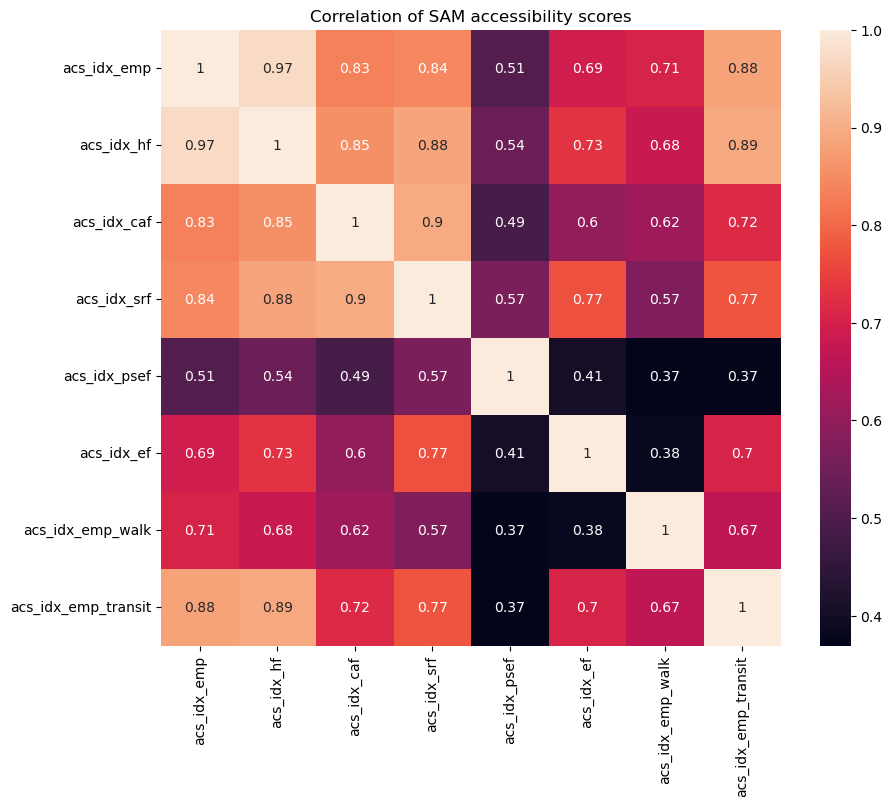

In [56]:
plt.figure(figsize = (10,8))
sns.heatmap(agg_counts[cols].corr(), annot=True)
plt.title('Correlation of SAM accessibility scores')
plt.show()

In [57]:
assert agg_counts['csd_pop_density'].isna().sum() == 0

Accessibility score is strongly correlated with CSD population density, both in the subset of locations in our dataset and across the entire country's SAM scores. 

In [58]:
np.corrcoef(sam_data.dropna(subset = 'csd_pop_density')['acs_idx_emp'], sam_data['csd_pop_density'].dropna())

array([[1.        , 0.78680045],
       [0.78680045, 1.        ]])

In [59]:
np.corrcoef(agg_counts['acs_idx_emp'], agg_counts['csd_pop_density'])

array([[1.        , 0.77811709],
       [0.77811709, 1.        ]])

## Regression model


Following Bolker 2015, we used a generalized linear mixed model (GLMM) to assess the relationship between the rate of people on bikes and independent variables of interest.


We used the lme4 package in R to fit our model. Model specification: `total bikes ~ year + SAM + Can-BICS + count session + (1|count location) + (1|observation), offset = count time in hours`. 

The count location was modeled as a random effect, since many locations have multiple counts over the years and across count sessions. We also included a random effect for each individual count observation as a way to model overdispersion in our data. Models  - this term essentially models increased variance in the data (cite Bolker). We included the count session as a fixed effect instead of a random effect to assess the influence of time of day on counts. 

In [60]:
from scipy import stats

In [61]:
data_subset = agg_counts.dropna(subset = ['can_bics_n', 'acs_idx_emp'])

In [62]:
data_subset['total_time_hours']=data_subset['total_time_seconds']/3600

In [63]:
data_subset.shape

(1665, 54)

In [64]:
data_subset['index'] = data_subset.reset_index().index

In [65]:
data_subset_norm = data_subset.copy()

In [66]:
# normalize to interquartile range

data_subset_norm['acs_idx_emp'] = (data_subset_norm['acs_idx_emp'] - data_subset_norm['acs_idx_emp'].mean()) / stats.iqr(data_subset['acs_idx_emp'])

# normalize these to have 0 be the first category, do not scale by iqr

for x in ['year', 'can_bics_n']:
    data_subset_norm[x] = (data_subset_norm[x] - data_subset_norm[x].min())

In [67]:
data_subset.to_csv("data_subset.csv", index = None)
data_subset_norm.to_csv("data_subset_norm.csv", index = None)

Try looking at canbics classes separately in model.

In [68]:
for infra in np.arange(6):
    d = data_subset[data_subset['can_bics_n'] == infra]
    d_norm = d.copy()     
    d_norm['acs_idx_emp'] = (d_norm['acs_idx_emp'] - d_norm['acs_idx_emp'].mean()) / stats.iqr(d['acs_idx_emp']) 
    d_norm['year'] = d_norm['year'] - d_norm['year'].min()
    print(d_norm.shape)
    d_norm.to_csv("data_subset_can_bics_{}.csv".format(infra), index = None)

(307, 55)
(112, 55)
(657, 55)
(448, 55)
(73, 55)
(68, 55)


What areas are representative of the mean accessibility?

In [69]:
stats.iqr(data_subset['acs_idx_emp'])

np.float64(0.1541216591930307)

In [70]:
data_subset['bikes_per_hour'].mean()

np.float64(64.28754736368435)

In [71]:
data_subset['acs_idx_emp'].mean()

np.float64(0.16020495192791048)

In [72]:
mean_acc_sites = data_subset[np.abs(data_subset['acs_idx_emp'] - data_subset['acs_idx_emp'].mean()) < 0.01]

This [website](https://library.virginia.edu/data/articles/interpreting-log-transformations-in-a-linear-model) and Bolker2015 says that when the response variable is logged, the exponent of the coefficient is the multiplicative change, i.e. for every 1-unit change in normalized can-bics score, the bike counts increase by 1.32 or 32%. 

For every 1-unit change in normalized SAM score (= 1 SD increase in SAM score), the bikes per hour increase by XX%, which at the mean bikes per hour would be YY bikes per hour

Or, for moving across the interquartile range of SAM, the bikes per hour increase by XX%, which at the mean would be YY bikes per hour.

How does this compare to the non-log model? These are similar to what the linear model says.

In [73]:
from statsmodels.stats.diagnostic import normal_ad

We added a random effect for each observation to control for over-dispersion of count data. Coefficient signs were unchanged. After this, overdispersion was not present (pearson squared residuals / residual degrees of freedom ~ 0.14). 

Note: the following checks require the R script to have been run

In [ ]:
resids_init = pd.read_csv("resids_pearson_init.csv")
resids = pd.read_csv("resids_pearson.csv")

resid_degrees_of_freedom = 1652 # 1665 observations - number of effects, from R model summary

for df in [resids_init, resids]:
    plt.hist(df, bins = 30)
    
    # sum of squares of pearson residuals, compare to residual degrees of freedom = 1469. If ratio >>1, overdispersed.
    print(np.sum(df**2, axis = 0) /resid_degrees_of_freedom)

    # test for normality
    print(normal_ad(df))

In [ ]:
fig, ax = plt.subplots()

ax.scatter(data_subset['bikes_per_hour'], resids_init, alpha = 0.2)
ax.set_xscale('log')

In [ ]:
fig, ax = plt.subplots()

ax.scatter(data_subset['bikes_per_hour'], resids, alpha = 0.2)

ax.set_xscale('log')